In [1]:
import torch
from torch import nn, optim
import torch.nn.functional as F

In [2]:
import numpy as np

In [3]:
import pandas as pd

In [4]:
import math

In [5]:
import matplotlib.pyplot as plt

In [6]:
from string import punctuation

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Baixe o pacote de dados necessário (apenas na primeira execução)
nltk.download('punkt_tab')

# 1. Baixe o pacote de dados de stopwords (necessário apenas na primeira vez)
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\anton\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anton\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [10]:
# 2. Carregue a lista de stopwords em inglês
stopwords_temp = stopwords.words('english')
stopwords_temp.extend( ['—', '’'] )
stopwords_ingles = set(stopwords_temp)
# stopwords_ingles

In [11]:
df = pd.read_csv("C:\\git\\dados\\nlp\\news_sentiment_analysis.csv", encoding="utf-8")
df = df[["Description"]]
df

,Description
0,"ST. GEORGE — Kaitlyn Larson, a first-year teac..."
1,"Harare, Zimbabwe – Local businesses are grappl..."
2,(marketscreener.com) Billionaire Elon Musk has...
3,(marketscreener.com) A U.S. trade regulator on...
4,4.5 million households in the U.S. have solar ...
...,...
3495,QRG Capital Management Inc. increased its stak...
3496,QRG Capital Management Inc. bought a new posit...
3497,QRG Capital Management Inc. boosted its stake ...
3498,"WESTFORD, Mass., July 18, 2024 /PRNewswire/ --..."


In [12]:
def limpar_texto( texto ):
    tokens_limpas = []
    tabela = str.maketrans("", "", punctuation)
    texto_limpo = texto.lower().translate( tabela )
    tokens = word_tokenize(texto_limpo)
    for token in tokens:
        if token not in stopwords_ingles:
            tokens_limpas.append( token )
    return " ".join(tokens_limpas)
            

In [13]:
limpar_texto(df["Description"][0])

'st george kaitlyn larson firstyear teacher pine view high school recently received best state award business leadership course larson students grades 1012 highest passing rate youscience exam spring fall semesters 2023 youscience exam similar final exams 8230'

In [14]:
df["descricao_limpa"] = df["Description"].apply( limpar_texto )
df

,Description,descricao_limpa
0,"ST. GEORGE — Kaitlyn Larson, a first-year teac...",st george kaitlyn larson firstyear teacher pin...
1,"Harare, Zimbabwe – Local businesses are grappl...",harare zimbabwe – local businesses grappling s...
2,(marketscreener.com) Billionaire Elon Musk has...,marketscreenercom billionaire elon musk donate...
3,(marketscreener.com) A U.S. trade regulator on...,marketscreenercom us trade regulator fridayann...
4,4.5 million households in the U.S. have solar ...,45 million households us solar panels homes cu...
...,...,...
3495,QRG Capital Management Inc. increased its stak...,qrg capital management inc increased stake sha...
3496,QRG Capital Management Inc. bought a new posit...,qrg capital management inc bought new position...
3497,QRG Capital Management Inc. boosted its stake ...,qrg capital management inc boosted stake akama...
3498,"WESTFORD, Mass., July 18, 2024 /PRNewswire/ --...",westford mass july 18 2024 prnewswire accordin...


In [15]:
MAX_PALAVRAS = 3000

In [16]:
vetorizador = CountVectorizer(max_features = MAX_PALAVRAS)

In [ ]:
"o motorista bateu o carro"

In [ ]:
[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1 ... ]

In [ ]:
[2, 3, 4, 2, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [ ]:
"o duende não quiz festa de natal este ano"

In [ ]:
[2, 13, 15, 1, 20, 8, 35, 42, 190, 0, 0, 0, 0, 0]

In [21]:
frases_selecionadas = df["descricao_limpa"].loc[0:50]
frases_selecionadas

0     st george kaitlyn larson firstyear teacher pin...
1     harare zimbabwe – local businesses grappling s...
2     marketscreenercom billionaire elon musk donate...
3     marketscreenercom us trade regulator fridayann...
4     45 million households us solar panels homes cu...
5     marketscreenercom billionaire investor mario g...
6     marketscreenercom july 12 2024 508 pm qwi anno...
7     marketscreenercom rome resources ltd pleased a...
8     business reporter potentially bruising fight g...
9     creative strategies deep industry knowledge sp...
10    ill drink kirland ellis partner flexes dexteri...
11    poughkeepsie – city poughkeepsie exploring pos...
12    marketscreenercom nerdwallet inc provides trus...
13    baltimore business journal hired ben terzi res...
14    marketscreenercom rosen law firm global invest...
15    footprints floors solano currently oneman oper...
16    footprints floors solano currently oneman oper...
17    living picturesque northern beaches sydney

In [22]:
dicionario = {"<PADDING>": 0, "<UNKNOWN>": 1}
dicionario

{'<PADDING>': 0, '<UNKNOWN>': 1}

In [31]:
frases_numeradas = []
contador_palavras = len(dicionario)
for frase in frases_selecionadas:
    frase_number = []
    tokens = word_tokenize(frase)
    for token in tokens:
        if token not in dicionario.keys():
            dicionario[token] = contador_palavras
            contador_palavras = contador_palavras + 1
        valor = dicionario[token]
        frase_number.append(valor)
    frases_numeradas.append(frase_number)
frases_numeradas

[[2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  5,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  26,
  27,
  32,
  33,
  34,
  35],
 [36, 37, 38, 39, 40, 41, 42, 43, 44, 45],
 [46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  49,
  50,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  52,
  75],
 [46,
  56,
  76,
  77,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  56,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104],
 [105,
  106,
  107,
  56,
  108,
  109,
  110,
  111,
  112,
  113,
  114,
  115,
  116,
  117,
  118,
  118,
  119,
  120,
  121,
  122,
  123,
  109,
  124,
  125,
  126,
  127,
  128,
  129,
  130,
  131,
  132,
  133,
  134,
  135,
  136,
  137,
  138,
  139,
  140,
  141,
  108,
  142,
  143,
  40,
  144,
  145,
  146,
  119],
 [46,
  47,

In [32]:
maior_frase = 0 
for frase in frases_numeradas:
    if len(frase) > maior_frase:
        maior_frase = len(frase)
maior_frase

72

In [35]:
# Fazer o padding
frases_padding = []
for frase in frases_numeradas:
    qtd_paddings = maior_frase - len(frase)
    paddings = [dicionario["<PADDING>"] for _ in range(qtd_paddings)]
    # padding na direita
    # frase.extend(paddings)
    # padding a esquerda
    frase = paddings + frase
    frases_padding.append(frase)
    print(frase)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 5, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 26, 27, 32, 33, 34, 35]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 49, 50, 68, 69, 70, 71, 72, 73, 74, 52, 75]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 46, 56, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 56, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104]
[0, 0, 0, 0, 0, 0, 0, 0,

[[0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  5,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  26,
  27,
  32,
  33,
  34,
  35],
 [0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45],
 [0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  5

In [ ]:

# Mapeamento das categorias
vocabulario = {    "positivo": 0,    "negativo": 1,    "neutro": 2}

# Categorias dos documentos
sentimentos = [    "positivo",    "negativo",    "positivo",    "neutro"]

# Convertendo para índices
indices = torch.tensor([    vocabulario[s] for s in sentimentos])

# Aplicando One-Hot Encodingencoded = F.one_hot(indices, num_classes=3)print(encoded)


In [21]:
X = vetorizador.fit_transform( df["descricao_limpa"] )
X.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(3500, 3000))

In [22]:
dicionario = vetorizador.get_feature_names_out()
dicionario

array(['000', '001', '038', ..., 'überkauft', 'überverkauft',
       'überwiegend'], shape=(3000,), dtype=object)

In [23]:
entrada = torch.tensor( X.toarray(), dtype=torch.float32 )
entrada

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

In [26]:
saida = torch.tensor( df["sentiment_number"], dtype=torch.float32 )
saida

tensor([[1., 0., 0.],
        [0., 1., 0.],
        [1., 0., 0.],
        ...,
        [1., 0., 0.],
        [0., 1., 0.],
        [1., 0., 0.]])

In [28]:
X_train, X_test, y_train, y_test = train_test_split(entrada, saida, test_size=0.25, random_state=50)

In [29]:
print("Shapes:")
print("X_train: ", X_train.shape)
print("Y_train: ", y_train.shape)
print("X_test: ", X_test.shape)
print("Y_test: ", y_test.shape)

Shapes:
X_train:  torch.Size([2625, 3000])
Y_train:  torch.Size([2625, 3])
X_test:  torch.Size([875, 3000])
Y_test:  torch.Size([875, 3])


In [30]:
modelo = nn.Sequential(
    nn.Linear(in_features = MAX_PALAVRAS, out_features = 512),
    nn.ReLU(),
    nn.Linear(in_features = 512, out_features = 3),
)
modelo

Sequential(
  (0): Linear(in_features=3000, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=3, bias=True)
)

In [31]:
perda = nn.CrossEntropyLoss()
perda

CrossEntropyLoss()

In [32]:
for param in modelo.parameters():
    print(param.data, " - ", param.data.shape)

tensor([[-0.0106, -0.0126, -0.0046,  ...,  0.0096, -0.0098, -0.0057],
        [-0.0101, -0.0019,  0.0156,  ..., -0.0141,  0.0050,  0.0167],
        [-0.0036,  0.0092,  0.0030,  ..., -0.0114, -0.0042, -0.0173],
        ...,
        [-0.0104,  0.0132, -0.0181,  ..., -0.0079,  0.0057, -0.0125],
        [ 0.0143,  0.0122, -0.0005,  ..., -0.0151, -0.0139,  0.0180],
        [-0.0069, -0.0033,  0.0172,  ..., -0.0136,  0.0178,  0.0148]])  -  torch.Size([512, 3000])
tensor([-1.7130e-02, -5.7787e-03,  6.3987e-03, -2.0688e-03, -4.0436e-03,
         9.3738e-03,  1.0498e-02, -9.7602e-03, -1.8066e-02, -1.6919e-02,
        -2.5642e-04,  2.7948e-03,  1.8127e-02, -1.0212e-02, -9.0945e-04,
        -5.0814e-03,  5.6584e-03, -7.1113e-03, -4.7597e-03, -5.0700e-03,
         8.2072e-03, -4.4631e-03, -2.3942e-04, -3.5327e-04, -9.8417e-03,
        -1.7827e-03,  3.3411e-03, -3.2936e-04, -6.7486e-03,  1.1028e-02,
        -7.2099e-04,  1.7012e-02, -1.7816e-02, -1.6077e-02, -1.5801e-02,
         1.6519e-02, -3.892

In [33]:
otimizador = optim.SGD( modelo.parameters(), lr = 0.1)
otimizador

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [34]:
epocas = 500
perdas = []
for epoca in range( epocas ):
    y_hat = modelo( X_train )
    loss = perda(y_hat, y_train)
    perdas.append( loss.tolist() )
    if epoca % 100 == 0:
        print(loss)
    otimizador.zero_grad()
    loss.backward()
    otimizador.step()

tensor(1.0799, grad_fn=<DivBackward1>)
tensor(0.7126, grad_fn=<DivBackward1>)
tensor(0.5313, grad_fn=<DivBackward1>)
tensor(0.3894, grad_fn=<DivBackward1>)
tensor(0.2869, grad_fn=<DivBackward1>)


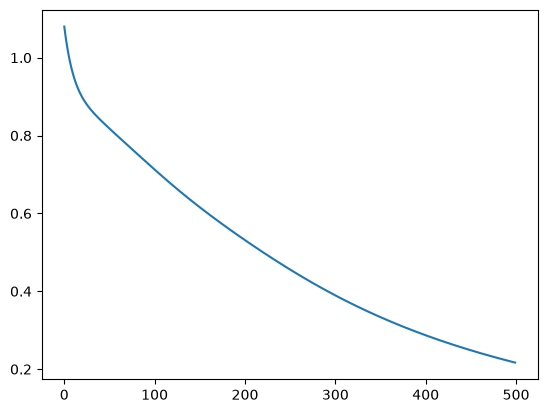

In [35]:
plt.plot( perdas )
plt.show()

In [36]:
vetorizador_teste = CountVectorizer(max_features=MAX_PALAVRAS, vocabulary=dicionario)

In [45]:
acertos = 0
y_hats_tests = modelo(X_test)
print(y_hats_tests[0:5])

tensor([[-0.4825,  0.7077, -0.1851],
        [ 4.4753, -3.0174, -1.4515],
        [ 4.0971, -3.0687, -1.1125],
        [-0.6135,  1.0781, -0.4385],
        [ 5.4227, -3.9007, -1.6153]], grad_fn=<SliceBackward0>)


In [46]:
y_hat_max = torch.argmax(y_hats_tests, axis=1)
print(y_hat_max[0:5])

tensor([1, 0, 0, 1, 0])


In [47]:
acertos = 0
y_hats_tests = modelo(X_test)
y_hats_tests_max = torch.argmax(y_hats_tests, axis=1)
y_test_max = torch.argmax(y_test, axis=1)
for idx, y_hat_test in enumerate(y_hats_tests):
    #               positivo   neutro     negativo
    # y_hat_test = [0.1,       0.05,      0.85]
    y_hat = y_hats_tests_max[idx]
    y = y_test_max[idx]  
    # y = y_test[idx]  = [0.0, 0.0, 1.0] 
    if y_hat == y:
        acertos = acertos + 1   
print(f"Porcentagem de acertos: {100*acertos/len(y_test):.2f}%")

Porcentagem de acertos: 84.11%


In [99]:
# acertos = 0
# for item_teste in range(1000, 2000):
#     # item_teste = 4
#     texto = df["descricao_limpa"][item_teste]
#     X_teste = vetorizador_teste.fit_transform( [texto] )
#     X_teste = torch.tensor(X_teste.toarray(), dtype=torch.float32)
#     y_hat = modelo(X_teste)
#     y = df["sentiment_number"][item_teste]
#     resultado = 1.0 if y_hat > 0.50 else 0.0
#     if resultado == y:
#         acertos = acertos + 1
#         # print("acertou")
#     else:
#         pass
#         # print("errou")
    
# print(f"Porcentagem de acertos: {100*acertos/1000:.2f}%")

Porcentagem de acertos: 99.90%


## Porcentagens de acerto:
Com 1 camada ==> 64.60% (500 epocas - lr 0.01)

Com 1 camada ==> 89.50% (15000 epocas - lr 0.01)

Com 1 camada ==> 95.70% (5000 epocas - lr 0.1)

Com 1 camada ==> 97.40% (10000 epocas - lr 0.1)

Com 2 camadas com 256 neuronios intermediarios ==> 58.40%  (500 epocas)

Com 2 camadas com 512 neuronios intermediarios ==> 99.90%  (2300 epocas)

Com 3 camadas com 512 e 64 neuronios intermediarios ==> 58.40% (500 epocas)

